# IaC-Eval: repair behaviour of IaCGOD (MAS) with GLM-5.3-Flash, plan-only deployment

In [1]:
import os, sys, glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
plt.style.use('ggplot'); sns.set_palette('muted')
sys.path.insert(0, 'audit')
import error_categories as ec
IAC = '..'
RUNS = f'{IAC}/runs/IaCEval_GLM53F_PlanOnly_runs'
OUT = f'{IAC}/results/repair_loop_tables'
CACHE = f'{IAC}/results/_analysis_cache'
r = pd.read_csv(f'{IAC}/results/TF_IaCEval_GLM53F_PlanOnly/results_final.csv', low_memory=False)
bench = pd.read_csv(f'{IAC}/data/iac_eval_benchmark.csv')[['row_number', 'difficulty']]
for d in (r, bench): d['row_number'] = d.row_number.astype(int)
r = r.merge(bench, on='row_number', how='left'); r['pass'] = r.final_validation_passed.astype(str).eq('True'); r['iters'] = r.iterations_used.astype(float)
assert len(r) == 458 and r.row_number.is_unique and r.validity.eq('valid_pass').all()
numbers = {}
print('rows', len(r), '| validity', r.validity.value_counts().to_dict(), '| runs folders found', sum(os.path.isdir(f'{RUNS}/{x}') for x in r.run_id), '| cache', os.path.exists(f'{CACHE}/msgs_TF_IaCEval_GLM53F_PlanOnly.pkl'))

rows 458 | validity {'valid_pass': 458} | runs folders found 0 | cache True


## 1. Headline: pass within n iterations, iterations, cost

In [2]:
N = (1, 2, 3, 4, 5, 7, 10, 15)
for n in N: numbers[f'passItr@{n} %'] = 100 * (r['pass'] & (r.iters <= n)).mean()
numbers.update({'tasks': len(r), 'passed': int(r['pass'].sum()), 'mean iterations': r.iters.mean(), 'median iterations': r.iters.median(), 'p90 iterations': r.iters.quantile(.9), 'max iterations': r.iters.max(),
                'first-attempt pass %': 100 * (r.iters == 1).mean(), 'mean ktokens/task': r.token_all_tokens.mean() / 1e3, 'median ktokens/task': r.token_all_tokens.median() / 1e3,
                'mean LLM calls/task': r.llm_calls_total.mean(), 'mean minutes/task': r.duration_seconds.mean() / 60, 'total hours': r.duration_seconds.sum() / 3600})
pd.Series(numbers).round(2).to_frame('value')

,value
passItr@1 %,49.56
passItr@2 %,81.66
passItr@3 %,96.07
passItr@4 %,99.13
passItr@5 %,99.56
passItr@7 %,100.00
passItr@10 %,100.00
passItr@15 %,100.00
tasks,458.00
passed,458.00


## 2. By difficulty level

,tasks,pass_pct,mean_iters,first_attempt_pct,ktokens,minutes
difficulty,,,,,,
1,45,100.0,1.7,53.3,36.4,6.2
2,95,100.0,1.7,49.5,27.0,4.5
3,113,100.0,1.7,49.6,34.5,6.1
4,58,100.0,1.8,50.0,52.2,8.3
5,72,100.0,1.6,55.6,42.3,7.9
6,75,100.0,2.0,41.3,76.7,12.0


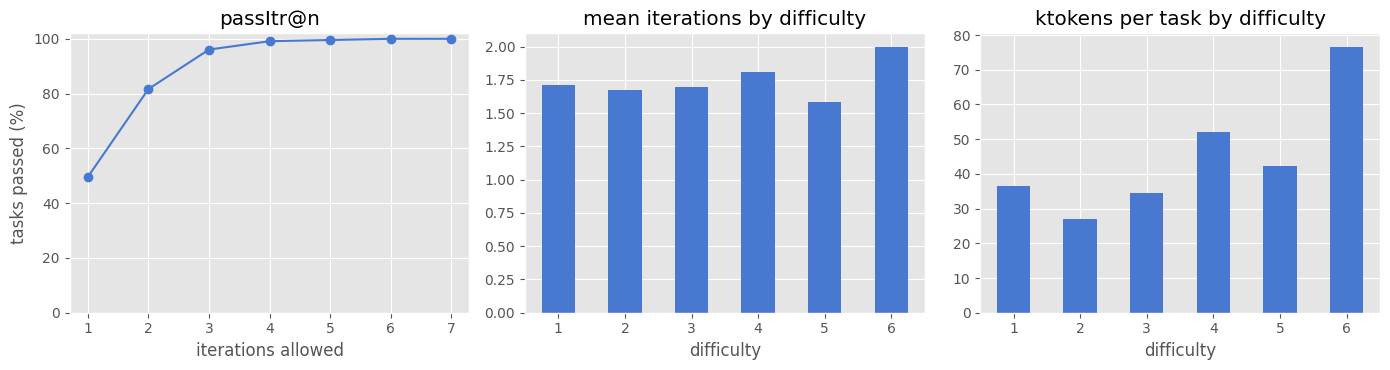

In [3]:
by = r.groupby('difficulty').agg(tasks=('row_number', 'size'), pass_pct=('pass', lambda s: 100*s.mean()), mean_iters=('iters', 'mean'), first_attempt_pct=('iters', lambda s: 100*(s == 1).mean()),
                                 ktokens=('token_all_tokens', lambda s: s.mean()/1e3), minutes=('duration_seconds', lambda s: s.mean()/60))
display(by.round(1)); by.round(3).to_csv(f'{OUT}/iaceval_planonly_by_difficulty.csv')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ns = list(range(1, 8)); ax[0].plot(ns, [100*(r['pass'] & (r.iters <= n)).mean() for n in ns], 'o-'); ax[0].set_xlabel('iterations allowed'); ax[0].set_ylabel('tasks passed (%)'); ax[0].set_title('passItr@n'); ax[0].set_ylim(0, 102)
by.mean_iters.plot.bar(ax=ax[1], rot=0); ax[1].set_title('mean iterations by difficulty'); by.ktokens.plot.bar(ax=ax[2], rot=0); ax[2].set_title('ktokens per task by difficulty')
plt.tight_layout(); plt.savefig('plots/iaceval_planonly_repair.png', dpi=150); plt.show()

## 3. What failed at the first attempt (documented error categories)

In [4]:
rids = sorted(r.run_id.astype(str)); p_msgs = f'{CACHE}/msgs_TF_IaCEval_GLM53F_PlanOnly.pkl'
index = {x: f'{RUNS}/{x}' for x in rids if os.path.isdir(f'{RUNS}/{x}')}
if len(index) < len(rids) and os.path.exists(p_msgs):
    c = pd.read_pickle(p_msgs); assert c['run_ids'] == rids; msgs = c['df']
else:
    msgs = ec.extract_messages(r.run_id, RUNS, 'TF', index); pd.to_pickle({'run_ids': rids, 'df': msgs}, p_msgs)
msgs['category'] = [ec.categorise('TF', c, s, k, sub, m, {})[0] for c, s, k, sub, m in zip(msgs.cls, msgs.stage, msgs.key, msgs['sub'], msgs.msg)]
first = msgs[msgs.iteration == msgs.groupby('run_id').iteration.transform('min')]
f1 = msgs[msgs.iteration == 1]
nfail1 = f1.run_id.nunique(); numbers['tasks failing the first attempt'] = nfail1
print(f'{nfail1} of {len(r)} tasks ({100*nfail1/len(r):.1f}%) failed the first attempt; their failing stage(s):')
st = f1.groupby('run_id').stage.agg(lambda s: sorted(set(s)))
display(st.astype(str).value_counts().to_frame('tasks'))
cat = f1.drop_duplicates(['run_id', 'category']).groupby('category').run_id.nunique().sort_values(ascending=False).to_frame('tasks')
cat['% of failing tasks'] = 100 * cat.tasks / nfail1; display(cat.round(1)); cat.round(2).to_csv(f'{OUT}/iaceval_planonly_first_attempt_categories.csv')
ident = f1.groupby(['category', 'key']).run_id.nunique().sort_values(ascending=False).head(12).to_frame('tasks'); display(ident)

231 of 458 tasks (50.4%) failed the first attempt; their failing stage(s):


,tasks
stage,
['terraform-validate'],224
['deploy'],7


,tasks,% of failing tasks
category,,
Invalid property or argument,165,71.4
Missing required property,52,22.5
Invalid reference or dependency,25,10.8
Invalid value or type,16,6.9
Malformed template,15,6.5
(unmapped),8,3.5
Resource configuration rejected by the provider,3,1.3
Missing value,2,0.9
Referenced resource or service not available,1,0.4


,,tasks
category,key,
Invalid property or argument,Unsupported argument,140
Missing required property,Missing required argument,41
Invalid property or argument,Unsupported block type,38
Invalid reference or dependency,Invalid resource type,24
Malformed template,"init: Unexpected ""aws"" block",12
Invalid property or argument,Unsupported attribute,9
Invalid value or type,Error in function call,6
Missing required property,Insufficient port_info blocks,4
Malformed template,init: Invalid character,3


## 4. Repair turns: how many errors a turn removes, and how long error episodes last

In [5]:
per = msgs.groupby(['run_id', 'iteration']).key.apply(lambda s: set(s)).reset_index(name='keys')
rows = []
for rid, g in per.groupby('run_id'):
    kd = dict(zip(g.iteration, g['keys']))
    for a, ka in kd.items():
        kb = kd.get(a + 1, set())
        rows.append((rid, a, len(ka), len(ka & kb), len(kb - ka), a + 1 in kd))
t = pd.DataFrame(rows, columns=['run_id', 'iteration', 'errors_before', 'errors_kept', 'errors_new', 'next_still_failing'])
epi = per.groupby('run_id').iteration.nunique()
print('failing iterations per task (tasks that failed at least once):'); display(epi.value_counts().sort_index().to_frame('tasks'))
numbers['mean failing iterations per failing task'] = epi.mean()
fixed_per_turn = (t.errors_before - t.errors_kept).mean(); new_per_turn = t.errors_new.mean()
numbers.update({'repair turns observed': len(t), 'errors removed per repair turn': fixed_per_turn, 'new errors introduced per repair turn': new_per_turn,
                'turns that introduce a new error %': 100 * (t.errors_new > 0).mean(), 'turns after which the task passes %': 100 * (~t.next_still_failing).mean(),
                'tasks whose first failure is fixed in one turn %': 100 * (epi == 1).sum() / len(epi)})
print(f'{len(t)} repair turns ({100*(~t.next_still_failing).mean():.1f}% end in a pass): {fixed_per_turn:.2f} errors removed and {new_per_turn:.2f} new errors per turn; {100*(t.errors_new>0).mean():.1f}% of turns add a new error')
print(f'{100*(epi==1).sum()/len(epi):.1f}% of tasks that failed once were fixed by the very next template')

failing iterations per task (tasks that failed at least once):


,tasks
iteration,
1,147
2,66
3,14
4,2
5,2


339 repair turns (68.1% end in a pass): 1.23 errors removed and 0.28 new errors per turn; 24.2% of turns add a new error
63.6% of tasks that failed once were fixed by the very next template


## 5. Planned resources, and tasks that pass with nothing planned

In [6]:
p_plan = f'{CACHE}/planned_TF_IaCEval_GLM53F_PlanOnly.csv'
if len(index) < len(rids) and os.path.exists(p_plan):
    r['planned'] = r.run_id.astype(str).map(pd.read_csv(p_plan, dtype={'run_id': str}).set_index('run_id').planned)
else:
    planned = []
    for x in r.run_id.astype(str):
        fs = sorted(glob.glob(f'{RUNS}/{x}/iteration_*.json')); j = json.load(open(fs[-1])); planned.append(len((j.get('deploy_validation_result') or {}).get('completed_resources') or []))
    r['planned'] = planned; r[['run_id', 'planned']].to_csv(p_plan, index=False)
print(f'planned resources in the final template: mean {r.planned.mean():.1f}, median {r.planned.median():.0f}, max {r.planned.max()}')
z = r[r.planned == 0]; numbers['tasks passing with zero planned resources'] = len(z); print('passing with zero planned resources:', z.row_number.tolist())
numbers['mean planned resources'] = r.planned.mean()

planned resources in the final template: mean 11.4, median 9, max 58
passing with zero planned resources: [124, 125]


## 6. Against the earlier DeepSeek-V4-Flash lint-only run on IaC-Eval

In [7]:
d = pd.read_csv(f'{IAC}/results/TF_IaCEval_DSV4F_LintOnly/results_final.csv', low_memory=False); d['row_number'] = d.row_number.astype(int)
d = d[d.validity.isin(['valid_pass', 'valid_fail'])]
m = r.merge(d, on='row_number', suffixes=('_glm', '_ds'))
x, y = m.iters, m.iterations_used_ds.astype(float)
print(f'common valid tasks: {len(m)}')
print(f'mean iterations: GLM plan-only {x.mean():.2f} vs DeepSeek lint-only {y.mean():.2f}; paired Wilcoxon p = {stats.wilcoxon(x, y).pvalue:.2e}')
print(f'first-attempt pass: GLM {100*(x==1).mean():.1f}% vs DeepSeek {100*(y==1).mean():.1f}%')
print(f'ktokens/task: {m.token_all_tokens_glm.mean()/1e3:.0f} vs {m.token_all_tokens_ds.mean()/1e3:.0f} | LLM calls: {m.llm_calls_total_glm.mean():.1f} vs {m.llm_calls_total_ds.mean():.1f}')
numbers.update({'DSV4F lint-only: common tasks': len(m), 'DSV4F lint-only mean iterations': y.mean(), 'DSV4F lint-only first-attempt %': 100*(y == 1).mean(), 'paired Wilcoxon p (iterations vs DSV4F)': stats.wilcoxon(x, y).pvalue})

common valid tasks: 367
mean iterations: GLM plan-only 1.75 vs DeepSeek lint-only 3.45; paired Wilcoxon p = 4.97e-28
first-attempt pass: GLM 48.5% vs DeepSeek 31.3%
ktokens/task: 44 vs 90 | LLM calls: 4.2 vs 9.4


## 7. Numbers for the thesis (also written to `iaceval_planonly_numbers.csv`)

In [8]:
N_ = pd.Series(numbers).to_frame('value'); N_.round(3).to_csv(f'{OUT}/iaceval_planonly_numbers.csv'); N_.round(2)

,value
passItr@1 %,49.56
passItr@2 %,81.66
passItr@3 %,96.07
passItr@4 %,99.13
passItr@5 %,99.56
passItr@7 %,100.00
passItr@10 %,100.00
passItr@15 %,100.00
tasks,458.00
passed,458.00
